# Predicting Customer Ride Cancellations: A Machine Learning Approach to Rideshare Marketplace Behavior

## Research question: Can we predict whether a customer will cancel a ride using trip, pricing, waiting-time, location, and customer/driver characteristics?

### Step 1 — Load and inspect the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Load the dataset
df = pd.read_csv("ncr_ride_bookings.csv") #found this on Kaggle

# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:") #lots of missingness for some variables
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("missing_count")
)

print("\nBooking status counts:")
display(df["Booking Status"].value_counts(dropna=False))

Dataset shape: (150000, 21)

Column names:
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']

First five rows:


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI



Data types:


Date                                     str
Time                                     str
Booking ID                               str
Booking Status                           str
Customer ID                              str
Vehicle Type                             str
Pickup Location                          str
Drop Location                            str
Avg VTAT                             float64
Avg CTAT                             float64
Cancelled Rides by Customer          float64
Reason for cancelling by Customer        str
Cancelled Rides by Driver            float64
Driver Cancellation Reason               str
Incomplete Rides                     float64
Incomplete Rides Reason                  str
Booking Value                        float64
Ride Distance                        float64
Driver Ratings                       float64
Customer Rating                      float64
Payment Method                           str
dtype: object


Missing values:


,missing_count
Incomplete Rides Reason,141000
Incomplete Rides,141000
Cancelled Rides by Customer,139500
Reason for cancelling by Customer,139500
Driver Cancellation Reason,123000
Cancelled Rides by Driver,123000
Customer Rating,57000
Driver Ratings,57000
Ride Distance,48000
Booking Value,48000



Booking status counts:


Booking Status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64

<Axes: >

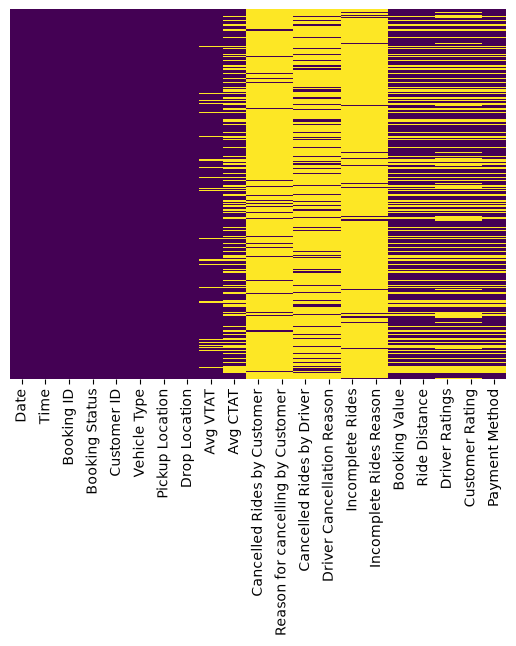

In [2]:
sns.heatmap(df.isnull(),yticklabels=False,cbar=False,cmap='viridis')

### Step 2 — Define the analytic sample and outcome
My primary outcome is:
- 1 = Cancelled by Customer
- 0 = Completed
I will not treat a driver cancellation or a booking with no driver as a customer non-cancellation. Those are different marketplace outcomes.


In [4]:
#inspect the outcome
print(df["Booking Status"].unique())
print(df["Booking Status"].value_counts(dropna=False))

<ArrowStringArray>
[      'No Driver Found',            'Incomplete',             'Completed',
   'Cancelled by Driver', 'Cancelled by Customer']
Length: 5, dtype: str
Booking Status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64


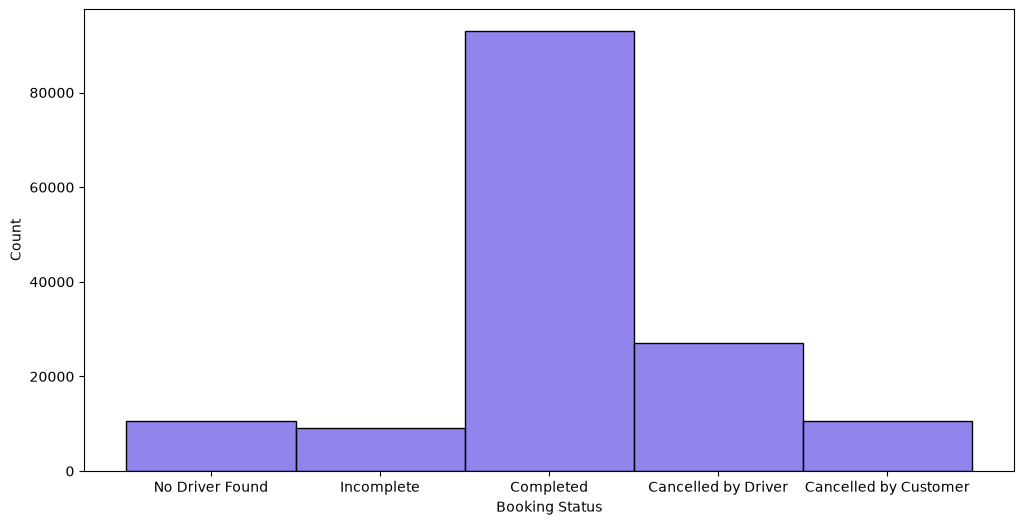

In [5]:
plt.figure(figsize=(12,6))
sns.histplot(df['Booking Status'],color='#6C5CE7')
plt.show()
# we are only interested in two categories : completed or cancelled by customer

In [6]:
# Keep only the two primary-analysis groups
analysis_df = df[
    df["Booking Status"].isin(["Cancelled by Customer", "Completed"])
].copy()

# Create the binary outcome
analysis_df["customer_cancelled"] = (
    analysis_df["Booking Status"] == "Cancelled by Customer"
).astype(int)

print(analysis_df["customer_cancelled"].value_counts(dropna=False))
print("Analytic sample size:", len(analysis_df))

customer_cancelled
0    93000
1    10500
Name: count, dtype: int64
Analytic sample size: 103500


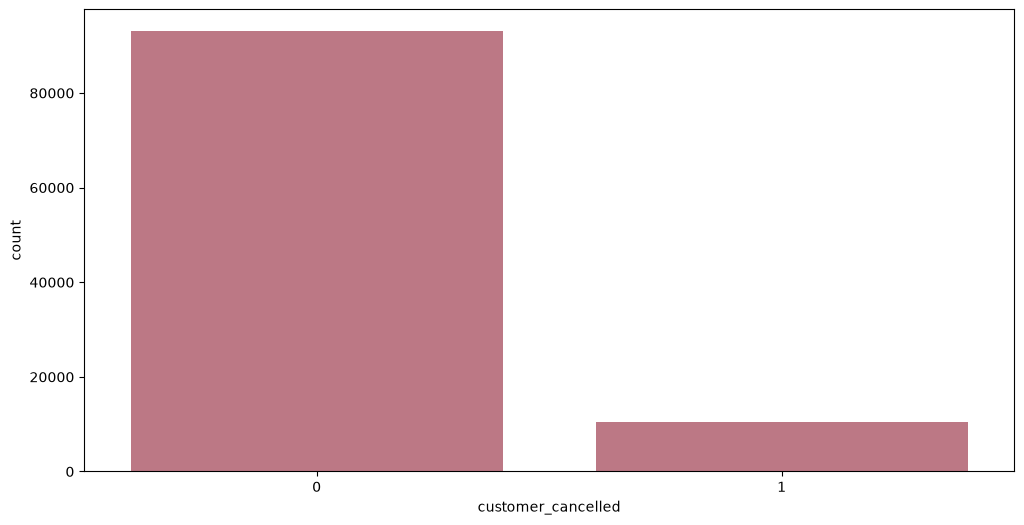

In [7]:
#plot the new outcome variable 
plt.figure(figsize=(12,6))
sns.countplot(
    data=analysis_df,
    x="customer_cancelled",
    color="#C76D7E"
)
plt.show()

## Step 3 — Audit target leakage and predictor availability

The fields below should not be model predictors because they directly reveal the outcome or are usually observed after the ride. IDs are also excluded as direct predictors.

`Avg VTAT`, `Avg CTAT`, and `Booking Value` require a timing check. In this first conservative model, they are excluded until we can verify that they were available when the prediction would be made...

In [8]:
leakage_or_exclusion_cols = [  # predictors not to use because they are post-outcome
    "Booking Status",
    "Cancelled Rides by Customer",
    "Reason for cancelling by Customer",
    "Cancelled Rides by Driver",
    "Driver Cancellation Reason",
    "Incomplete Rides",
    "Incomplete Rides Reason",
    "Customer Rating",
    "Driver Ratings",
    "Booking ID", #identifier
    "Customer ID",#identifier
    "Payment Method" #Not available before outcome
]

candidate_predictors = [
    "Vehicle Type", "Pickup Location", "Drop Location",
    "Ride Distance", "Booking Value", "Avg VTAT", "Avg CTAT",
     "Date", "Time"
]

print("Exclusion columns present:",
      [c for c in leakage_or_exclusion_cols if c in analysis_df.columns])

print("Candidate columns present:",
      [c for c in candidate_predictors if c in analysis_df.columns])


# Numeric variables
numeric_cols = [
    "Avg VTAT",
    "Avg CTAT",
    "Booking Value",
    "Ride Distance"
]

for col in numeric_cols:
    if col in analysis_df.columns:
        print(f"\n{col} by outcome:")
        display(
            analysis_df.groupby("Booking Status", dropna=False)[col]
            .agg(["count", "mean", "median"])
        )

Exclusion columns present: ['Booking Status', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Customer Rating', 'Driver Ratings', 'Booking ID', 'Customer ID', 'Payment Method']
Candidate columns present: ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Ride Distance', 'Booking Value', 'Avg VTAT', 'Avg CTAT', 'Date', 'Time']

Avg VTAT by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,10500,12.512381,12.6
Completed,93000,8.511878,8.5



Avg CTAT by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,0,NaN,NaN
Completed,93000,30.034772,30.0



Booking Value by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,0,NaN,NaN
Completed,93000,508.178215,414.0



Ride Distance by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,0,NaN,NaN
Completed,93000,26.000493,26.02



Avg VTAT by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,10500,12.512381,12.6
Completed,93000,8.511878,8.5


## Step 4 — Clean dates and time features

In [9]:
#combine date with time
analysis_df["Date"] = pd.to_datetime(analysis_df["Date"], errors="coerce")
print(analysis_df["Date"])
analysis_df["Time_parsed"] = pd.to_timedelta(analysis_df["Time"], errors="coerce")
analysis_df["booking_datetime"] = (
    analysis_df["Date"] + analysis_df["Time_parsed"]
)
print(analysis_df["booking_datetime"])


analysis_df["hour"] = analysis_df["booking_datetime"].dt.hour
analysis_df["day_of_week"] = analysis_df["booking_datetime"].dt.dayofweek
analysis_df["month"] = analysis_df["booking_datetime"].dt.month
analysis_df["is_weekend"] = (analysis_df["day_of_week"] >= 5).astype("Int64")
analysis_df["is_peak"] = (
    analysis_df["hour"].between(7, 9) |
    analysis_df["hour"].between(17, 19)
).astype("Int64")

2        2024-08-23
3        2024-10-21
4        2024-09-16
5        2024-02-06
6        2024-06-17
            ...    
149995   2024-11-11
149996   2024-11-24
149997   2024-09-18
149998   2024-10-05
149999   2024-03-10
Name: Date, Length: 103500, dtype: datetime64[us]
2        2024-08-23 08:56:10
3        2024-10-21 17:17:25
4        2024-09-16 22:08:00
5        2024-02-06 09:44:56
6        2024-06-17 15:45:58
                 ...        
149995   2024-11-11 19:34:01
149996   2024-11-24 15:55:09
149997   2024-09-18 10:55:15
149998   2024-10-05 07:53:34
149999   2024-03-10 15:38:03
Name: booking_datetime, Length: 103500, dtype: datetime64[us]


## Step 5 — Exploratory data 

Customer cancellation rate in the sample: 10.14%


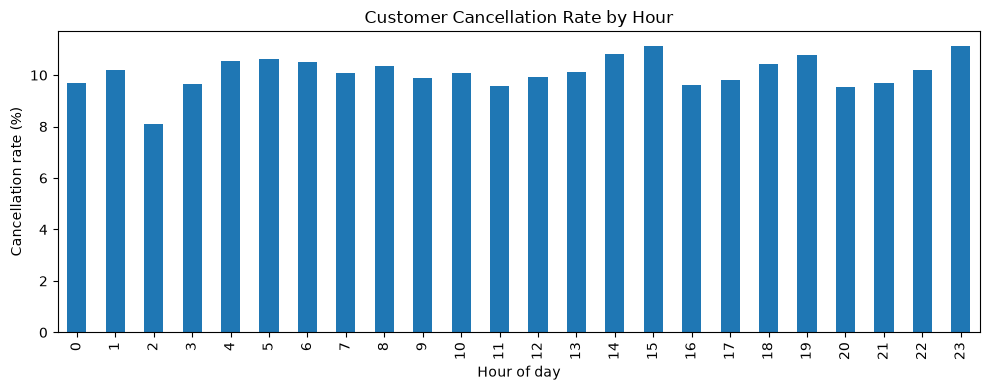


Ride Distance by outcome:


,count,mean,median,std
Booking Status,,,,
Cancelled by Customer,0,NaN,NaN,NaN
Completed,93000,26.0,26.02,13.82



Avg VTAT by outcome:


,count,mean,median,std
Booking Status,,,,
Cancelled by Customer,10500,12.51,12.6,4.34
Completed,93000,8.51,8.5,3.75



Booking Value by outcome:


,count,mean,median,std
Booking Status,,,,
Cancelled by Customer,0,NaN,NaN,NaN
Completed,93000,508.18,414.0,396.06



Cancellation rate by Vehicle Type:


,bookings,cancellation_rate
Vehicle Type,,
Uber XL,3110,0.105
Auto,25835,0.104
Go Mini,20646,0.102
Premier Sedan,12518,0.101
Bike,15609,0.101
eBike,7274,0.099
Go Sedan,18508,0.099



Cancellation rate by Payment Method:


,bookings,cancellation_rate
Payment Method,,
NaN,10500,1.0
Cash,23114,0.0
Credit Card,9320,0.0
Debit Card,7526,0.0
UPI,41834,0.0
Uber Wallet,11206,0.0


In [10]:
print(f"Customer cancellation rate in the sample: "
      f"{analysis_df['customer_cancelled'].mean():.2%}")

hourly_rate = analysis_df.groupby("hour", dropna=False)["customer_cancelled"].mean() * 100
hourly_rate.plot(kind="bar", figsize=(10, 4))
plt.title("Customer Cancellation Rate by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Cancellation rate (%)")
plt.tight_layout()
plt.show()


for col in ["Ride Distance", "Avg VTAT", "Booking Value"]:
    if col in analysis_df.columns:
        print(f"\n{col} by outcome:")
        display(analysis_df.groupby("Booking Status")[col]
                .agg(["count", "mean", "median", "std"]).round(2))

for col in ["Vehicle Type", "Payment Method"]:
    if col in analysis_df.columns:
        print(f"\nCancellation rate by {col}:")
        display(analysis_df.groupby(col, dropna=False)["customer_cancelled"]
                .agg(bookings="size", cancellation_rate="mean")
                .sort_values("cancellation_rate", ascending=False)
                .round(3))

In [11]:
print(analysis_df.columns)

Index(['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID',
       'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT',
       'Avg CTAT', 'Cancelled Rides by Customer',
       'Reason for cancelling by Customer', 'Cancelled Rides by Driver',
       'Driver Cancellation Reason', 'Incomplete Rides',
       'Incomplete Rides Reason', 'Booking Value', 'Ride Distance',
       'Driver Ratings', 'Customer Rating', 'Payment Method',
       'customer_cancelled', 'Time_parsed', 'booking_datetime', 'hour',
       'day_of_week', 'month', 'is_weekend', 'is_peak'],
      dtype='str')


<Axes: >

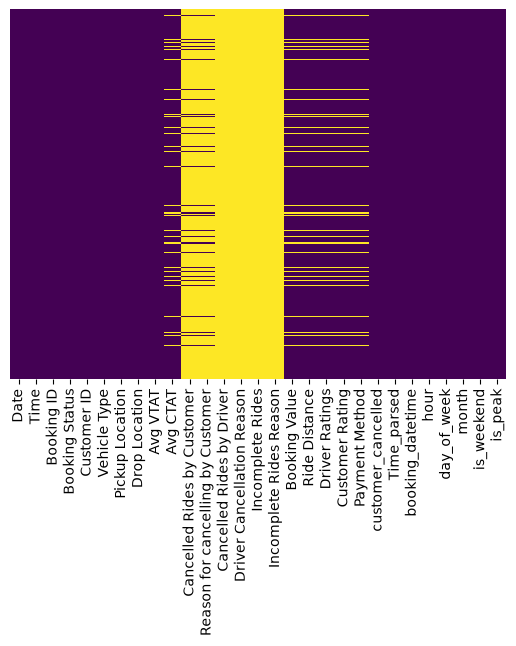

In [12]:
#checking missingness
sns.heatmap(analysis_df.isnull(),yticklabels=False,cbar=False,cmap='viridis')

## Step 6 — Logistic model 

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
X = analysis_df[
    [
        "Avg VTAT",
        "hour",
        "day_of_week",
        "Vehicle Type",
        "Pickup Location",
        "Drop Location"    ]
]

y = analysis_df["customer_cancelled"]


# 1. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=101
)

# 2. Identify numeric and categorical variables
numeric_features = [
    "Avg VTAT",
    "hour",
    "day_of_week"
]

categorical_features = [
    "Vehicle Type",
    "Pickup Location",
    "Drop Location"
]

X_train_numeric = X_train[numeric_features]
X_test_numeric = X_test[numeric_features]

X_train_categorical = X_train[categorical_features]
X_test_categorical = X_test[categorical_features]

#3. Deal with missing numerical values
numeric_medians = X_train_numeric.median()
X_train_numeric = X_train_numeric.fillna(numeric_medians)
X_test_numeric = X_test_numeric.fillna(numeric_medians)

#4. Standardize numerical variables
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_numeric_scaled = scaler.fit_transform(X_train_numeric)
X_test_numeric_scaled = scaler.transform(X_test_numeric)

#5. Deal with categorical variables
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)
X_train_cat_encoded = encoder.fit_transform(
    X_train_categorical
)
X_test_cat_encoded = encoder.transform(
    X_test_categorical
)

# 6. Combine both
import numpy as np

X_train_final = np.hstack([
    X_train_numeric_scaled,
    X_train_cat_encoded
])
X_test_final = np.hstack([
    X_test_numeric_scaled,
    X_test_cat_encoded
])
#7. Train Logistic Regression Model
from sklearn.linear_model import LogisticRegression

logmodel = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# 8. Fit the model
logmodel.fit(
    X_train_final,
    y_train
)
# 8. Make predictions
predictions = logmodel.predict(X_test_final)
# 9. Look at the actual and predicted values
print(y_test.values)
print(predictions)

[0 0 1 ... 0 0 0]
[0 0 1 ... 0 0 0]


In [13]:
predictions = logmodel.predict(X_test_final)

predictions2 = logmodel.predict(X_train_final)

print("Test predictions:")
print(predictions)

print("Training predictions:")
print(predictions2)

Test predictions:
[0 0 1 ... 0 0 0]
Training predictions:
[0 1 0 ... 0 0 0]


In [15]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

print("Test accuracy:", accuracy_score(y_test, predictions))

[[18410  9477]
 [ 1161  2002]]
              precision    recall  f1-score   support

           0       0.94      0.66      0.78     27887
           1       0.17      0.63      0.27      3163

    accuracy                           0.66     31050
   macro avg       0.56      0.65      0.52     31050
weighted avg       0.86      0.66      0.72     31050

Test accuracy: 0.6573913043478261


## Step 7 — Linear SVM model 

In [18]:
from sklearn.svm import LinearSVC

# Create the Linear SVM model
svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42,
    max_iter=2000
)

# Train the model
svm_model.fit(
    X_train_final,
    y_train
)

# Make predictions on the test data
svm_pred = svm_model.predict(
    X_test_final
)
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, svm_pred))


# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        svm_pred,
        target_names=[
            "Completed",
            "Cancelled by Customer"
        ],
        zero_division=0
    )
)


# Accuracy
print(
    "Test Accuracy:",
    accuracy_score(y_test, svm_pred)
)

Confusion Matrix:
[[18479  9408]
 [ 1170  1993]]

Classification Report:
                       precision    recall  f1-score   support

            Completed       0.94      0.66      0.78     27887
Cancelled by Customer       0.17      0.63      0.27      3163

             accuracy                           0.66     31050
            macro avg       0.56      0.65      0.53     31050
         weighted avg       0.86      0.66      0.73     31050

Test Accuracy: 0.6593236714975845


## Step 8 — XGBoost model
This one can account for nonlinearity

In [23]:
from xgboost import XGBClassifier
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

print("Completed rides:", negative_count)
print("Cancelled rides:", positive_count) 
#cancelled rides are far less common than completed rides, so we will give it more weight

Completed rides: 65113
Cancelled rides: 7337


In [24]:
scale_pos_weight = negative_count / positive_count

print("Scale positive weight:", scale_pos_weight)

Scale positive weight: 8.87460815047022


In [25]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

In [26]:
xgb_model.fit(
    X_train_final,
    y_train
)
xgb_pred = xgb_model.predict(X_test_final)

In [27]:
#evaluate the xgb model
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=[
            "Completed",
            "Cancelled by Customer"
        ],
        zero_division=0
    )
)

# Accuracy
print(
    "Test Accuracy:",
    round(accuracy_score(y_test, xgb_pred), 3)
)

Confusion Matrix:
[[26048  1839]
 [ 1900  1263]]

Classification Report:
                       precision    recall  f1-score   support

            Completed       0.93      0.93      0.93     27887
Cancelled by Customer       0.41      0.40      0.40      3163

             accuracy                           0.88     31050
            macro avg       0.67      0.67      0.67     31050
         weighted avg       0.88      0.88      0.88     31050

Test Accuracy: 0.88


In [28]:
xgb_prob = xgb_model.predict_proba(X_test_final)[:, 1]

xgb_auc = roc_auc_score(
    y_test,
    xgb_prob
)

print("ROC-AUC:", round(xgb_auc, 3))

ROC-AUC: 0.752


## Step 9 — Model Comparison

In [30]:
# Logistic Regression
logit_pred = logmodel.predict(X_test_final)
logit_prob = logmodel.predict_proba(X_test_final)[:, 1]


# Linear SVM
svm_pred = svm_model.predict(X_test_final)
svm_score = svm_model.decision_function(X_test_final)


# XGBoost
xgb_pred = xgb_model.predict(X_test_final)
xgb_prob = xgb_model.predict_proba(X_test_final)[:, 1]

In [31]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

In [32]:
# Logistic Regression

logit_auc = roc_auc_score(y_test, logit_prob)
logit_ap = average_precision_score(y_test, logit_prob)
logit_precision = precision_score(y_test, logit_pred, zero_division=0)
logit_recall = recall_score(y_test, logit_pred, zero_division=0)
logit_f1 = f1_score(y_test, logit_pred, zero_division=0)
logit_accuracy = accuracy_score(y_test, logit_pred)


# Linear SVM

svm_auc = roc_auc_score(y_test, svm_score)
svm_ap = average_precision_score(y_test, svm_score)
svm_precision = precision_score(y_test, svm_pred, zero_division=0)
svm_recall = recall_score(y_test, svm_pred, zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, zero_division=0)
svm_accuracy = accuracy_score(y_test, svm_pred)


# XGBoost

xgb_auc = roc_auc_score(y_test, xgb_prob)
xgb_ap = average_precision_score(y_test, xgb_prob)
xgb_precision = precision_score(y_test, xgb_pred, zero_division=0)
xgb_recall = recall_score(y_test, xgb_pred, zero_division=0)
xgb_f1 = f1_score(y_test, xgb_pred, zero_division=0)
xgb_accuracy = accuracy_score(y_test, xgb_pred)

In [33]:
import pandas as pd

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "XGBoost"
    ],

    "ROC-AUC": [
        logit_auc,
        svm_auc,
        xgb_auc
    ],

    "Average Precision": [
        logit_ap,
        svm_ap,
        xgb_ap
    ],

    "Precision": [
        logit_precision,
        svm_precision,
        xgb_precision
    ],

    "Recall": [
        logit_recall,
        svm_recall,
        xgb_recall
    ],

    "F1": [
        logit_f1,
        svm_f1,
        xgb_f1
    ],

    "Accuracy": [
        logit_accuracy,
        svm_accuracy,
        xgb_accuracy
    ]
})

model_results = model_results.round(3)

print(model_results)

                 Model  ROC-AUC  Average Precision  Precision  Recall     F1  \
0  Logistic Regression    0.740              0.446      0.174   0.633  0.273   
1           Linear SVM    0.741              0.448      0.175   0.630  0.274   
2              XGBoost    0.752              0.492      0.407   0.399  0.403   

   Accuracy  
0     0.657  
1     0.659  
2     0.880  


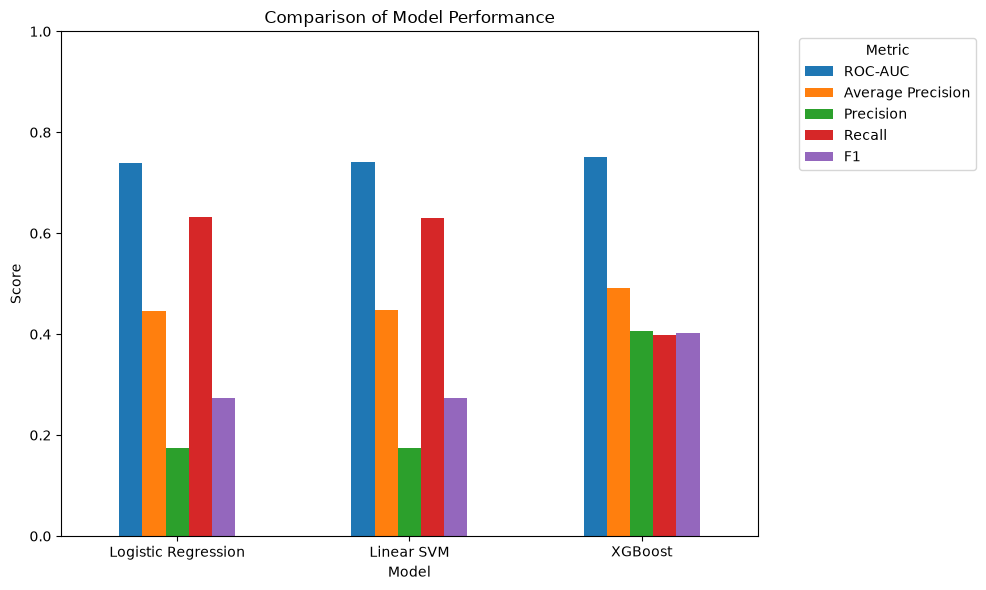

In [34]:
import matplotlib.pyplot as plt

# Create the graph for comparison of model performance
model_results.plot(
    x="Model",
    y=[
        "ROC-AUC",
        "Average Precision",
        "Precision",
        "Recall",
        "F1"
    ],
    kind="bar",
    figsize=(10, 6)
)

# Add labels
plt.title("Comparison of Model Performance")
plt.xlabel("Model")
plt.ylabel("Score")

# Put legend outside the graph
plt.legend(
    title="Metric",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

## Step 10 — Interpretation
**XGBoost** has the highest ROC-AUC, precision, F1 score, and Accurancy. So based on these metrics, XGBoost performs better than Logistic Regression and Linear SVM. However, when you look at the recall rate, the linear models are much better at finding customers who actually cancel. But they do this by predicting a lot of customers as cancellations who don't actually cancel, which explains their very low precision (~17%).

Although XGBoost has the highest accuracy, my outcome is imbalanced: customer cancellations are much less common than completed rides. As such, accuracy isn't the most useful metric by itself. XGBoost achieved the highest ROC-AUC (0.752), average precision (0.492), precision (0.407), and F1 score (0.403), indicating better overall discrimination and a better balance between precision and recall than the linear models. 

So i would say that XGBoost is the preferred model based on overall predictive performance. Yet, logistic Regression and Linear SVM have substantially higher recall, meaning they are better if the primary goal is to identify as many potential customer cancellations as possible.

Now I wonder, **which model and probability threshold provide the best balance between identifying cancellations and avoiding false alerts?**


## Step 11 — XGBoost threshold analysis


   Threshold  Precision  Recall     F1  Accuracy
0        0.3      0.129   0.992  0.228     0.315
1        0.4      0.134   0.922  0.234     0.384
2        0.5      0.407   0.399  0.403     0.880
3        0.6      0.947   0.346  0.507     0.931
Best threshold based on F1:
Threshold    0.600
Precision    0.947
Recall       0.346
F1           0.507
Accuracy     0.931
Name: 3, dtype: float64


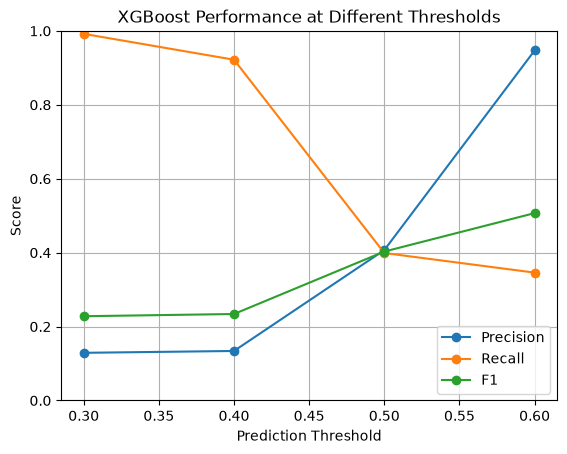

In [37]:
# Get the probability that each ride will be cancelled
xgb_prob = xgb_model.predict_proba(X_test_final)[:, 1]
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

thresholds = [0.3, 0.4, 0.5, 0.6]

results = []

for threshold in thresholds:

    # Convert probability into 0 or 1
    xgb_pred = (xgb_prob >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(y_test, xgb_pred, zero_division=0)
    recall = recall_score(y_test, xgb_pred, zero_division=0)
    f1 = f1_score(y_test, xgb_pred, zero_division=0)
    accuracy = accuracy_score(y_test, xgb_pred)

    # Save results
    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Accuracy": accuracy
    })
import pandas as pd

threshold_results = pd.DataFrame(results)

threshold_results = threshold_results.round(3)

print(threshold_results)

best_threshold = threshold_results.loc[
    threshold_results["F1"].idxmax()
]

print("Best threshold based on F1:")
print(best_threshold)

import matplotlib.pyplot as plt

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Prediction Threshold")
plt.ylabel("Score")
plt.title("XGBoost Performance at Different Thresholds")

plt.ylim(0, 1)
plt.legend()
plt.grid(True)

plt.show()

The 0.6 threshold produced the highest F1 score among the evaluated thresholds, with a precision of 94.7% and recall of 34.6%. This doesn't mean the 0.6 threshold is essentially "better", it will depend on the research question I want to answer. 

For instance, if I want a model that finds as many cancellations as possible, 0.3–0.4 is attractive.

If I want a model that says "I'm highly confident this customer will cancel", 0.6 is much better.